## Introduction
Problems statement: Prediciting the Depth of the water based on physical features

## Exploratory Analysis


In [280]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
sns.set_theme(palette="colorblind")

There are 2 csv files in the current version of the dataset:


In [281]:
print(os.listdir('../data/'))

['cast.csv', '.placeholder', 'hello']


### Let's check 1st file: ../input/bottle.csv

In [282]:
nRowsRead = 1000 # specify 'None' if want to read whole file
# bottle.csv may have more rows in reality, but we are only loading/previewing the first 1000 rows
df1 = pd.read_csv('../data/cast.csv', delimiter=',', nrows = nRowsRead,encoding='iso-8859-1')
df1.dataframeName = 'bottle.csv'
nRow, nCol = df1.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 1000 rows and 62 columns


Let's take a quick look at what the data looks like:

In [283]:
df1.head(5)

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,...,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,...,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,...,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,...,0.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,4,054.0 056.0,19-4903CR-HY-060-0930-05400560-0019A-3,19,10.45,33.420,NaN,25.643,NaN,...,0.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,5,054.0 056.0,19-4903CR-HY-060-0930-05400560-0020A-7,20,10.45,33.421,NaN,25.643,NaN,...,0.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Distribution graphs (histogram/bar graph) of sampled columns:

In [284]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 62 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Cst_Cnt              1000 non-null   int64  
 1   Btl_Cnt              1000 non-null   int64  
 2   Sta_ID               1000 non-null   object 
 3   Depth_ID             1000 non-null   object 
 4   Depthm               1000 non-null   int64  
 5   T_degC               998 non-null    float64
 6   Salnty               970 non-null    float64
 7   O2ml_L               0 non-null      float64
 8   STheta               968 non-null    float64
 9   O2Sat                0 non-null      float64
 10  Oxy_µmol/Kg          0 non-null      float64
 11  BtlNum               0 non-null      float64
 12  RecInd               1000 non-null   int64  
 13  T_prec               998 non-null    float64
 14  T_qual               10 non-null     float64
 15  S_prec               970 non-null    fl

In [285]:
df1.describe()

,Cst_Cnt,Btl_Cnt,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,...,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
count,1000.000000,1000.000000,1000.000000,998.000000,970.000000,0.0,968.000000,0.0,0.0,0.0,...,973.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,16.803000,500.500000,329.604000,8.408657,33.668295,NaN,26.106232,NaN,NaN,NaN,...,0.548027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,9.500972,288.819436,346.635231,3.237212,0.509149,NaN,0.855427,NaN,NaN,NaN,...,0.460203,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,1.000000,0.000000,2.780000,32.630000,NaN,23.706000,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,9.000000,250.750000,50.000000,5.482500,33.220500,NaN,25.182250,NaN,NaN,NaN,...,0.140000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,16.000000,500.500000,189.500000,8.430000,33.748000,NaN,26.239000,NaN,NaN,NaN,...,0.420000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,25.000000,750.250000,515.250000,11.342500,34.108750,NaN,26.888000,NaN,NaN,NaN,...,0.900000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,33.000000,1000.000000,1352.000000,19.760000,34.650000,NaN,27.581000,NaN,NaN,NaN,...,1.700000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We remove columns who have more than half of the samples as na

In [286]:
for col in df1.columns:
    if df1[col].isna().sum() >= 1000/2:
        df1 = df1.drop(col,axis=1)
    

In [287]:
def get_na_cols(df=df1):
    for col in df.columns:
        na_count = df[col].isna().sum() 
        if  na_count > 0 :
            print(col," , ",na_count)
            


In [288]:
for col in df1.columns:
    print( col )

Cst_Cnt
Btl_Cnt
Sta_ID
Depth_ID
Depthm
T_degC
Salnty
STheta
RecInd
T_prec
S_prec
P_qual
O_qual
O2Satq
Chlqua
Phaqua
PO4q
SiO3qu
NO2q
NO3q
NH3q
C14A1q
C14A2q
DarkAq
MeanAq
R_Depth
R_TEMP
R_Sal
R_DYNHT


In [289]:
get_na_cols(df1)

T_degC  ,  2
Salnty  ,  30
STheta  ,  32
T_prec  ,  2
S_prec  ,  30
R_TEMP  ,  38
R_Sal  ,  55
R_DYNHT  ,  27


# Filling na values
## Starting with Depthm

In [290]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def box_plot_per_cast_for_col(x,df=df1):
    df_clean = df.dropna(subset=[x])
    selected_casts = df_clean['Cst_Cnt'].unique()
    df_subset = df_clean[df_clean['Cst_Cnt'].isin(selected_casts)]

    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=df_subset,
        x='Cst_Cnt',
        y=x,
        hue='Cst_Cnt',
        legend=False,
    )
    plt.title(
        x+' Variation Across Individual Casts',
        fontsize=14,
        pad=12,
    )
    plt.xlabel('Cast Count (Cst_Cnt)', fontsize=12)
    plt.ylabel(x, fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

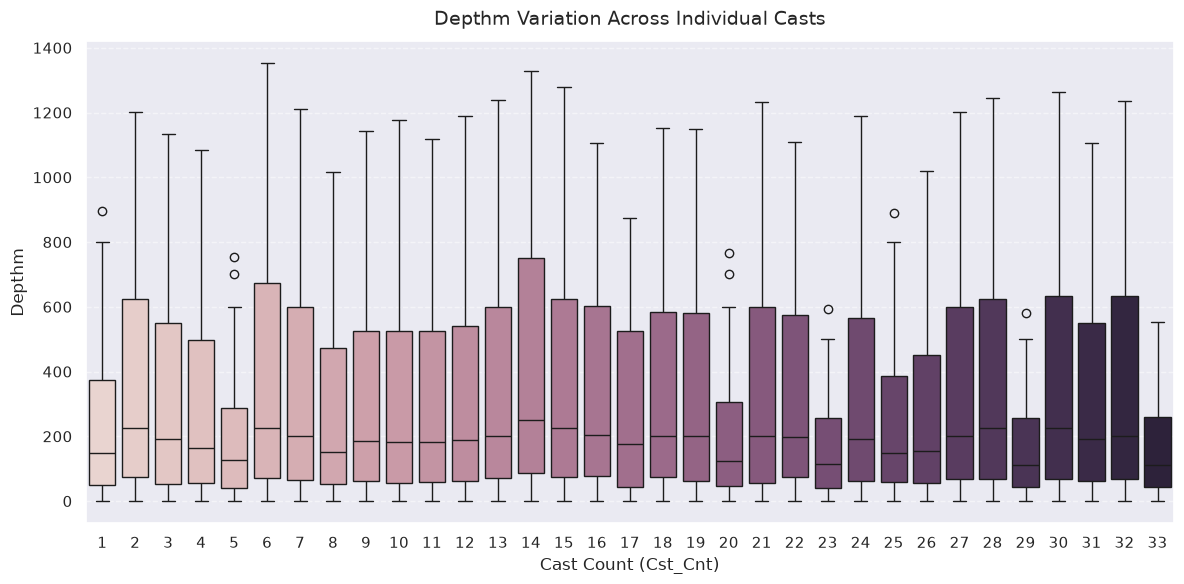

In [291]:
box_plot_per_cast_for_col('Depthm')

No outliers detected

<Axes: xlabel='Depthm', ylabel='Density'>

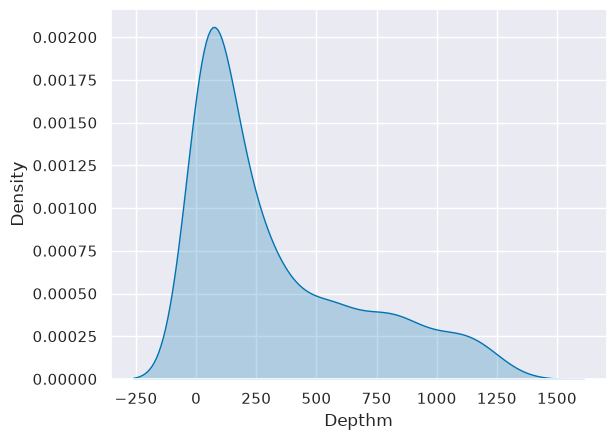

In [292]:
sns.kdeplot(df1.Depthm,fill=True)

In [293]:
df1['Depthm'].fillna(df1['Depthm'].median(),inplace=True)

Text(0.5, 1.0, 'Imputed By Linear Interpolation Vs Orginal Salinity Values')

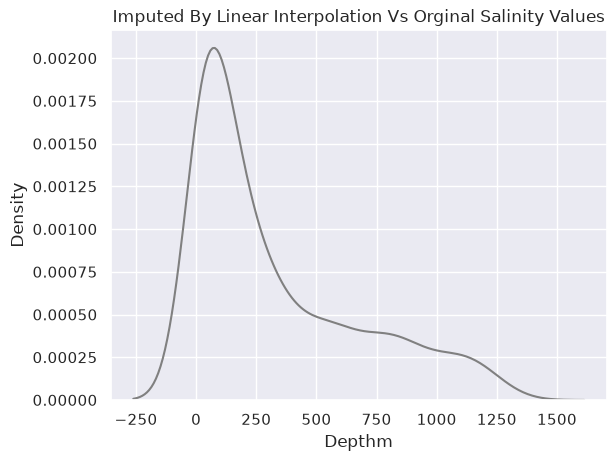

In [294]:
sns.kdeplot(df1.Depthm,color='Gray')
plt.title("Imputed By Linear Interpolation vs Orginal Salinity values".title())

## Filling T_degC

<Axes: xlabel='T_degC', ylabel='Density'>

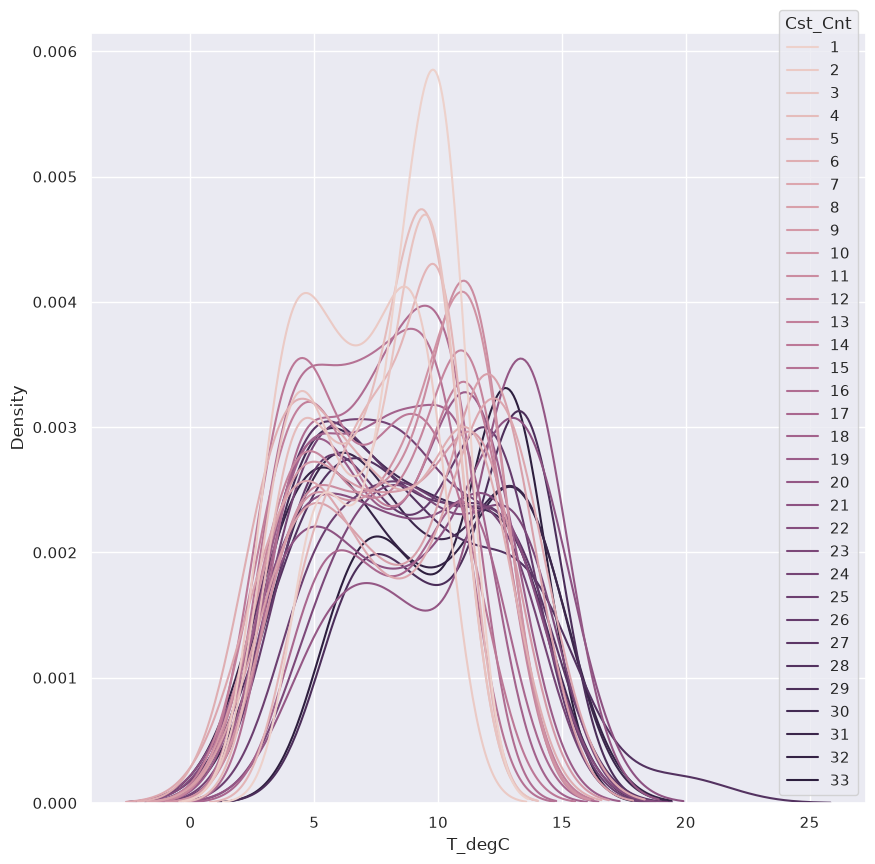

In [295]:
plt.figure(figsize=(10,10))
sns.kdeplot(df1,x="T_degC",hue=df1.Cst_Cnt)

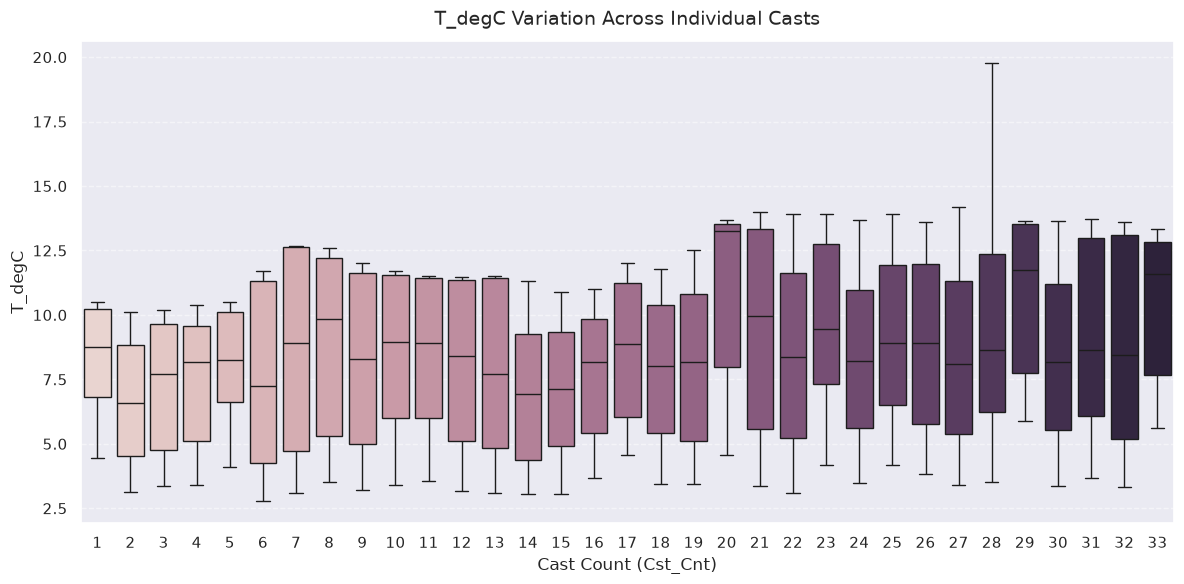

In [296]:
box_plot_per_cast_for_col('T_degC')

In [297]:
df1['T_degC'] = df1.groupby('Cst_Cnt')['T_degC'].transform(lambda group: group.interpolate(method='linear',limit_direction='both'))

In [298]:
df1.dropna(subset=['R_Sal'],inplace=True)

# Training Model

In [299]:
not_needed_cols =  ['RecInd','O2Satq','Chlqua','Phaqua','Sta_ID','Cst_Cnt','Btl_Cnt','Depth_ID','PO4q','NO2q','NO3q','NH3q','C14A1q','C14A2q','DarkAq','MeanAq','SiO3qu']
for col in df1.columns:
    if 'qual' in col or 'prec' in col or col in not_needed_cols:
        df1 = df1.drop(col, axis=1)

In [300]:
df1.head(5)

,Depthm,T_degC,Salnty,STheta,R_Depth,R_TEMP,R_Sal,R_DYNHT
0,0,10.50,33.440,25.649,0,10.50,233.0,0.00
1,8,10.46,33.440,25.656,8,10.46,232.5,0.01
2,10,10.46,33.437,25.654,10,10.46,232.8,0.02
3,19,10.45,33.420,25.643,19,10.45,234.1,0.04
4,20,10.45,33.421,25.643,20,10.45,234.0,0.04


<Axes: >

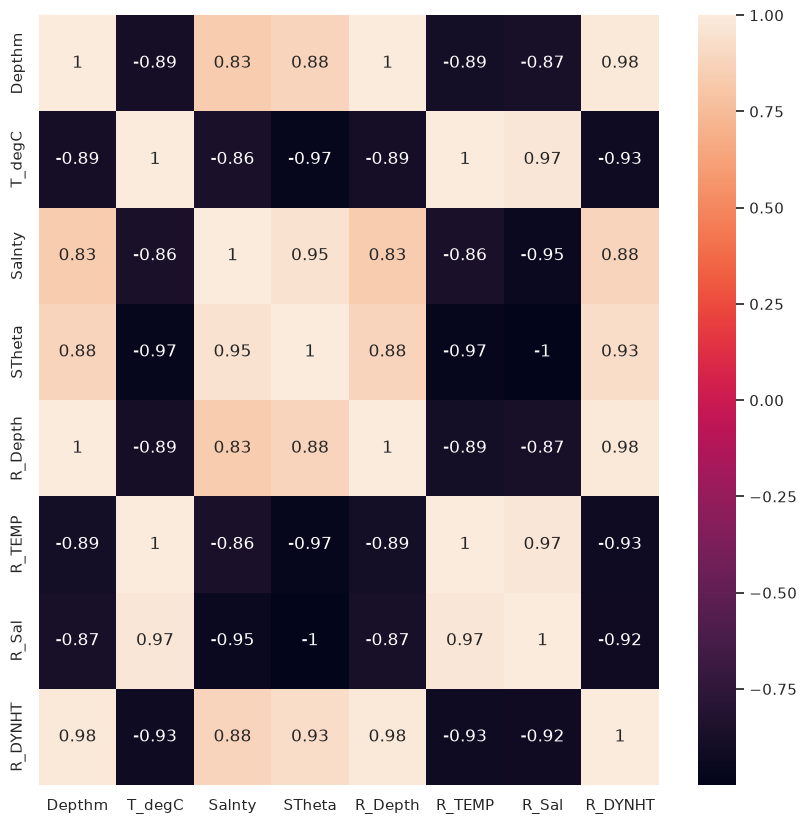

In [301]:
plt.figure(figsize=(10,10))
sns.heatmap(df1.corr(),annot=True)

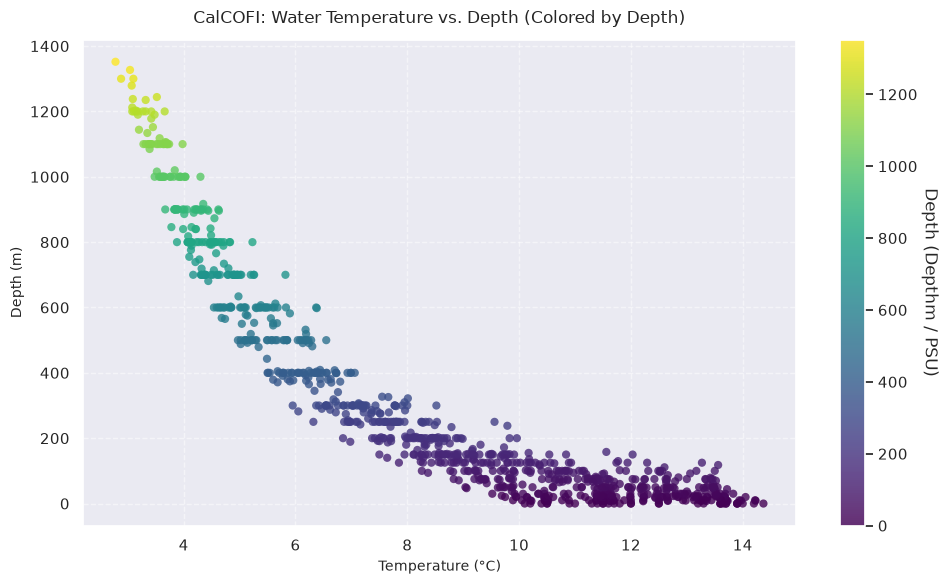

In [302]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
plt.figure(figsize=(10, 6))

# Scatter plot: T_degC vs Depthm, colored by Depthm
scatter = plt.scatter(
    x=df2['T_degC'],
    y=df2['Depthm'],
    c=df2['Depthm'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='none',
    s=35
)

# Invert Y-axis so surface (0m) is at the top

# Add Colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Depth (Depthm / PSU)', rotation=270, labelpad=15)

# Axis labels and title
plt.title('CalCOFI: Water Temperature vs. Depth (Colored by Depth)', fontsize=12, pad=12)
plt.xlabel('Temperature (°C)', fontsize=10)
plt.ylabel('Depth (m)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

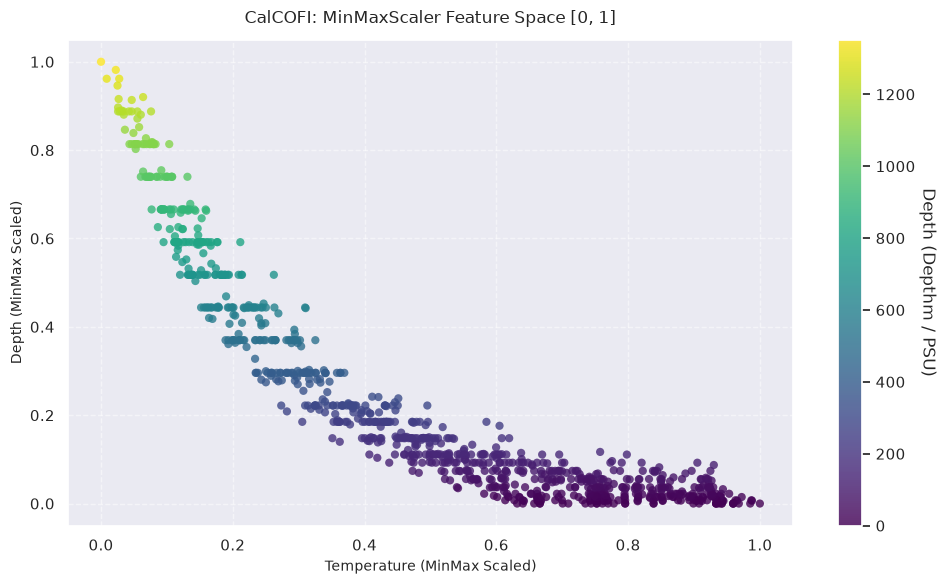

In [303]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# 1. Apply MinMaxScaler (preserves bimodal distribution shape strictly between 0 and 1)
minmax_scaler = MinMaxScaler()
X_minmax = minmax_scaler.fit_transform(df1[['T_degC', 'Depthm']])

# 2. Plot MinMax scaled feature space
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    x=X_minmax[:, 0], # Scaled Temperature [0, 1]
    y=X_minmax[:, 1], # Scaled Depth [0, 1]
    c=df1['Depthm'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='none',
    s=35
)


cbar = plt.colorbar(scatter)
cbar.set_label('Depth (Depthm / PSU)', rotation=270, labelpad=15)

plt.title('CalCOFI: MinMaxScaler Feature Space [0, 1]', fontsize=12, pad=12)
plt.xlabel('Temperature (MinMax Scaled)', fontsize=10)
plt.ylabel('Depth (MinMax Scaled)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [304]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Select clean physical predictors (No leaked identity variables)
features = ['Depthm', 'T_degC']
target = 'R_Sal'

# 2. Drop NaNs across selected columns
df_reg = df1.dropna(subset=features + [target]).copy()

X = df_reg[features]
y = df_reg[target]

# 3. 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Dataset split successfully: Train={X_train.shape[0]}, Test={X_test.shape[0]}")

Dataset split successfully: Train=756, Test=189


In [309]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

models_and_params = {
    "Linear Regression": (
        Pipeline([('scaler', MinMaxScaler()), ('model', LinearRegression())]),
        {}
    ),
    "Ridge Regression": (
        Pipeline([('scaler', MinMaxScaler()), ('model', Ridge())]),
        {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
    ),
    "Lasso Regression": (
        Pipeline([('scaler', MinMaxScaler()), ('model', Lasso(max_iter=5000))]),
        {'model__alpha': [0.001, 0.01, 0.1, 1.0]}
    ),
    "ElasticNet Regression": (
        Pipeline([('scaler', MinMaxScaler()), ('model', ElasticNet(max_iter=5000))]),
        {'model__alpha': [0.01, 0.1, 1.0], 'model__l1_ratio': [0.2, 0.5, 0.8]}
    ),
    "Polynomial Regression": (
        Pipeline([('poly', PolynomialFeatures()), ('scaler', StandardScaler()), ('model', LinearRegression())]),
        {'poly__degree': [2, 3]}
    ),
    "Decision Tree Regressor": (
        Pipeline([('model', DecisionTreeRegressor(random_state=42))]),
        {'model__max_depth': [3, 5, 10, None]}
    ),
    "Random Forest Regressor": (
        Pipeline([('model', RandomForestRegressor(random_state=42))]),
        {'model__n_estimators': [50, 100, 200]}
    ),
    "Gradient Boosting Regressor": (
        Pipeline([('model', GradientBoostingRegressor(random_state=42))]),
        {'model__learning_rate': [0.01, 0.05, 0.1], 'model__n_estimators': [100, 200]}
    ),
    "Support Vector Regressor (SVR)": (
        Pipeline([('scaler', MinMaxScaler()), ('model', SVR())]),
        {'model__C': [0.1, 1.0, 10.0], 'model__kernel': ['linear', 'rbf']}
    ),
    "K-Nearest Neighbors Regressor": (
        Pipeline([('scaler', MinMaxScaler()), ('model', KNeighborsRegressor())]),
        {'model__n_neighbors': [3, 5, 7, 11]}
    )
}

best_fitted_models = {}

for name, (pipeline, param_grid) in models_and_params.items():
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=5,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_fitted_models[name] = grid.best_estimator_
    print(f"Trained {name}")

Trained Linear Regression
Trained Ridge Regression
Trained Lasso Regression
Trained ElasticNet Regression
Trained Polynomial Regression
Trained Decision Tree Regressor
Trained Random Forest Regressor
Trained Gradient Boosting Regressor
Trained Support Vector Regressor (SVR)
Trained K-Nearest Neighbors Regressor


In [310]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

summary_results = []

for name, model in best_fitted_models.items():
    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    
    summary_results.append({
        'Algorithm': name,
        'R² Score': round(r2, 4),
        'RMSE': round(rmse, 4),
        'MAE': round(mae, 4)
    })

# Ranked by R2 score as required by Section C2 rubric
summary_df = pd.DataFrame(summary_results).sort_values(by='R² Score', ascending=False)
print("=== REGRESSION TRACK SUMMARY TABLE ===")
print(summary_df.to_string(index=False))

=== REGRESSION TRACK SUMMARY TABLE ===
                     Algorithm  R² Score    RMSE     MAE
 K-Nearest Neighbors Regressor    0.9861  9.4859  6.8998
   Gradient Boosting Regressor    0.9848  9.9199  7.1517
       Random Forest Regressor    0.9832 10.4593  7.6015
Support Vector Regressor (SVR)    0.9816 10.9194  7.3707
         Polynomial Regression    0.9813 11.0197  7.7844
       Decision Tree Regressor    0.9806 11.2272  7.7641
              Ridge Regression    0.9434 19.1739 14.5854
             Linear Regression    0.9434 19.1743 14.5818
              Lasso Regression    0.9433 19.1955 14.5247
         ElasticNet Regression    0.9417 19.4598 15.3386


In [311]:
from sklearn.model_selection import cross_val_score

top_2_names = summary_df.head(2)['Algorithm'].tolist()
top_2_results = []

for name in top_2_names:
    model = best_fitted_models[name]
    y_pred = model.predict(X_test)
    
    # Test Metrics
    r2_test = r2_score(y_test, y_pred)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
    mae_test = mean_absolute_error(y_test, y_pred)
    
    # Mandatory 5-Fold Cross-Validated R2
    cv_r2 = cross_val_score(model, X_train, y_train, cv=5, scoring='r2', n_jobs=-1)
    
    top_2_results.append({
        'Top Model': name,
        'Test R²': round(r2_test, 4),
        'Test RMSE': round(rmse_test, 4),
        'Test MAE': round(mae_test, 4),
        '5-Fold CV R² (Mean ± Std)': f"{cv_r2.mean():.4f} ± {cv_r2.std():.4f}"
    })

top_2_df = pd.DataFrame(top_2_results)
print("\n=== TOP 2 MODELS MANDATORY METRICS ===")
print(top_2_df.to_string(index=False))


=== TOP 2 MODELS MANDATORY METRICS ===
                    Top Model  Test R²  Test RMSE  Test MAE 5-Fold CV R² (Mean ± Std)
K-Nearest Neighbors Regressor   0.9861     9.4859    6.8998           0.9775 ± 0.0026
  Gradient Boosting Regressor   0.9848     9.9199    7.1517           0.9773 ± 0.0033


Calculating Permutation Importances...


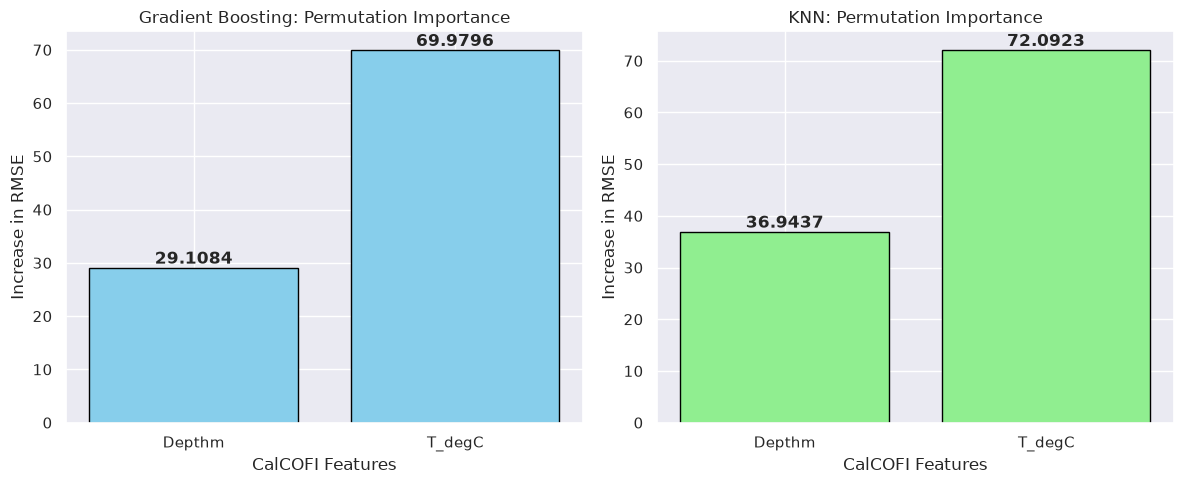


Gradient Boosting Native Importances:
Depthm: 0.1653
T_degC: 0.8347


In [313]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import permutation_importance

# 1. Define your feature names based on your CalCOFI subset
feature_names = ['Depthm', 'T_degC']

# 2. Extract your two best models from the dictionary created in the GridSearchCV loop
gb_model = best_fitted_models["Gradient Boosting Regressor"]
knn_model = best_fitted_models["K-Nearest Neighbors Regressor"]

# 3. Calculate Permutation Importance for both models
# Note: It is best practice to use your test set (X_test, y_test) for this
print("Calculating Permutation Importances...")
gb_importance = permutation_importance(
    gb_model, X_test, y_test, n_repeats=10, random_state=42, scoring='neg_root_mean_squared_error'
)
knn_importance = permutation_importance(
    knn_model, X_test, y_test, n_repeats=10, random_state=42, scoring='neg_root_mean_squared_error'
)

# 4. Set up the visualization (Side-by-side bar charts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot Gradient Boosting Importance
# We use importances_mean to get the average drop in performance across the 10 repeats
ax1.bar(feature_names, gb_importance.importances_mean, color='skyblue', edgecolor='black')
ax1.set_title('Gradient Boosting: Permutation Importance')
ax1.set_ylabel('Increase in RMSE')
ax1.set_xlabel('CalCOFI Features')

# Plot KNN Importance
ax2.bar(feature_names, knn_importance.importances_mean, color='lightgreen', edgecolor='black')
ax2.set_title('KNN: Permutation Importance')
ax2.set_ylabel('Increase in RMSE')
ax2.set_xlabel('CalCOFI Features')

# Add exact values on top of the bars for clarity
for ax, importances in zip([ax1, ax2], [gb_importance, knn_importance]):
    for i, v in enumerate(importances.importances_mean):
        ax.text(i, v, f'{v:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# OPTIONAL: How to get Gradient Boosting's native importance
# ---------------------------------------------------------
# Since you used a pipeline, you have to access the model step specifically
gb_native_importances = gb_model.named_steps['model'].feature_importances_
print("\nGradient Boosting Native Importances:")
for name, val in zip(feature_names, gb_native_importances):
    print(f"{name}: {val:.4f}")